In [5]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

from sklearn.model_selection import train_test_split
import torch
import zipfile
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import cv2
import glob
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import torchvision.models as models
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import seaborn as sns
from sklearn.decomposition import PCA


# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
#for dirname, _, filenames in os.walk('/kaggle/input'):
 #   for filename in filenames:
  #      print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

['/kaggle/input/bnb-images/0.jpg', '/kaggle/input/bnb-images/1.jpg', '/kaggle/input/bnb-images/2.jpg', '/kaggle/input/bnb-images/3.jpg', '/kaggle/input/bnb-images/4.jpg', '/kaggle/input/bnb-images/5.jpg', '/kaggle/input/bnb-images/6.jpg', '/kaggle/input/bnb-images/7.jpg', '/kaggle/input/bnb-images/8.jpg', '/kaggle/input/bnb-images/9.jpg']


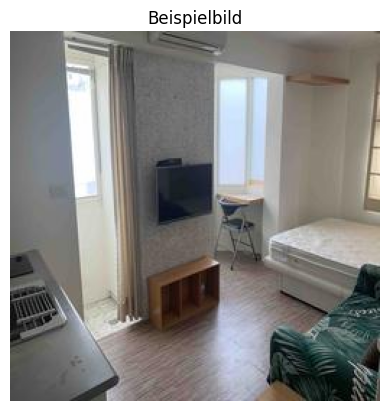

In [6]:
bnb_images = "/kaggle/input/bnb-images"
import glob

image_paths = glob.glob("/kaggle/input/bnb-images/*.jpg")
all_images = sorted(image_paths, key=lambda x: int(os.path.splitext(os.path.basename(x))[0]))

print(all_images[:10])

img = cv2.imread(all_images[0])

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Plot
plt.imshow(img_rgb)
plt.axis('off')
plt.title("Beispielbild")
plt.show()


In [7]:
print(len(all_images))

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                         std=[0.229, 0.224, 0.225])
])

class Image_dataset(Dataset):
    def __init__(self, paths, transform=None):
        self.paths = paths
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img

5977


In [16]:

def Cnnmodel(image_df):

    images = Image_dataset(image_df, transform = transform)
    dataloader = DataLoader(images, batch_size=64, shuffle=False)

    model = models.resnet18(pretrained=True)
    model.eval()
# letzte Klassifikationsschicht für nur Features
    feature_extractor = torch.nn.Sequential(*list(model.children())[:-1])

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    feature_extractor = feature_extractor.to(device)

# Feature extraction
    all_features = []

    with torch.no_grad():
        for batch_imgs in dataloader:
            batch_imgs = batch_imgs.to(device)
            features = feature_extractor(batch_imgs)
            features = features.view(features.size(0), -1)  # Flatten
            all_features.append(features.cpu())

# Alle Features zu einem Tensor
    all_features = torch.cat(all_features, dim=0)
    features_numpy = all_features.numpy()
    print(f"Feature-Matrix Größe: {all_features.shape}")  # (samples, Features)
    return features_numpy
features_np = Cnnmodel(all_images)    

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Feature-Matrix Größe: torch.Size([5977, 512])


Spalten ohne Varianz: []


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


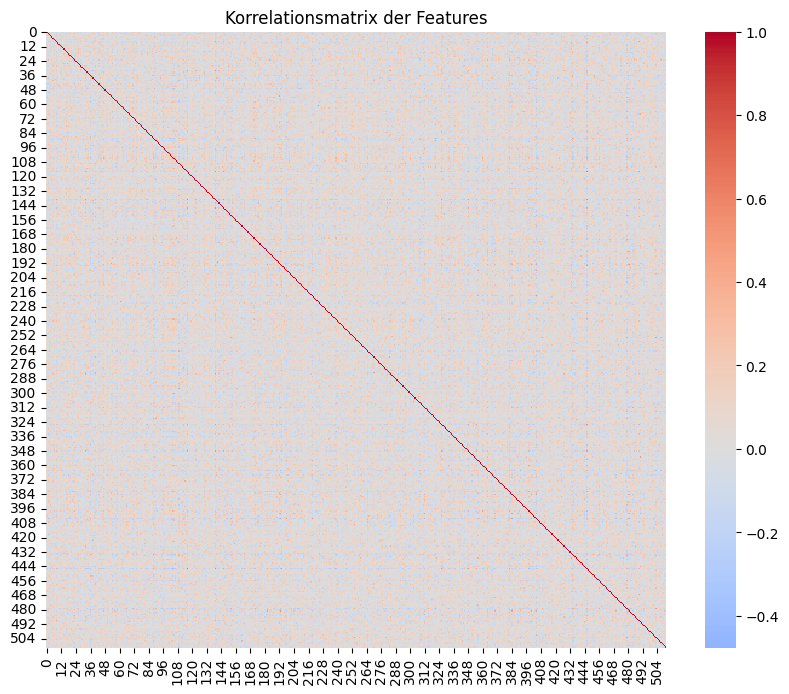

In [17]:
df = pd.DataFrame(features_np)
zero_var_cols = df.columns[df.std() == 0]
print(f"Spalten ohne Varianz: {zero_var_cols.tolist()}")
corr = df.corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title("Korrelationsmatrix der Features")
plt.show()

In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
features_scaled = scaler.fit_transform(features_np)
pca = PCA(n_components=0.94)  # 94% Varianz beibehalten
features_pca = pca.fit_transform(features_scaled)

print("Reduzierte Shape:", features_pca.shape)

pca_df = pd.DataFrame(features_pca)
pca_df.to_csv("feature_matrix.csv", index=False)

Reduzierte Shape: (5977, 253)
